In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import pyogrio
import numpy as np

# Ruta basada en tu terminal actual (~/big-data-postgraduate)
REPO = os.path.expanduser("~/big-data-postgraduate")
RAW = os.path.join(REPO, "kit/data/raw")
OUT = os.path.join(REPO, "kit/salidas/soluciones/PD04")

os.makedirs(OUT, exist_ok=True)

print("Entradas (RAW):", RAW)
print("Salidas (OUT):", OUT)
print("pandas:", pd.__version__, "| GeoPandas:", gpd.__version__)

suelo = pd.read_csv(
    os.path.join(RAW, "agrosavia.csv"),
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(suelo.head())
print(suelo.shape)

territorio = pd.read_csv(
    os.path.join(RAW, "divipola.csv"),
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(territorio.head())
print(territorio.shape)

Entradas (RAW): /home/tuptc/big-data-postgraduate/kit/data/raw
Salidas (OUT): /home/tuptc/big-data-postgraduate/kit/salidas/soluciones/PD04
pandas: 2.2.3 | GeoPandas: 1.2.0


,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


(92738, 32)


,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,"-75,702188","6,038708"


(1122, 7)


In [2]:
# 1. Diagnostico y contrato

# Asignación de id_fila basado en el índice asignado por pandas (posiciones únicas de la copia CSV)
suelo["id_fila"] = suelo.index.astype(str)


# Función auxiliar para evaluar cadenas limpias de espacios
def contar_vacios_tras_strip(df):
  conteo = {}
  for col in df.columns:
    if df[col].dtype == "object":
      conteo[col] = (df[col].astype(str).str.strip() == "").sum()
    else:
      conteo[col] = 0
  return pd.Series(conteo)


# Diagnósticar AGROSAVIA (sobre los datos de suelo...)
diag_suelo = pd.DataFrame({
    "Tipo Original": suelo.dtypes,  # ¿Qué tipo son? (cada columna)
    "Nulos (NaN/None)": suelo.isna().sum(),  # ¿Cuántos nulos por columna?
    'Textos Vacíos ("")': (suelo == "").sum(),  # ¿Existen celdas vacías?
    "Vacíos tras strip()": contar_vacios_tras_strip(suelo),  # Vacíos tras retirar espacios
    'Marcadores "ND"': (suelo == "ND").sum(),})  # ¿Hay celdas marcadas con ND?

# Diagnosticar Divipola
diag_territorio = pd.DataFrame({
    "Tipo Original": territorio.dtypes,
    "Nulos (NaN/None)": territorio.isna().sum(),
    'Textos Vacíos ("")': (territorio == "").sum(),
    "Vacíos tras strip()": contar_vacios_tras_strip(territorio),
    'Marcadores "ND"': (territorio == "ND").sum(),})

print(" Resumen: ")
print(f"Filas de AGROSAVIA: {len(suelo)}")
print(f"Filas de DIVIPOLA:  {len(territorio)}\n")

print(" Diagnóstico de AGROSAVIA ")
display(diag_suelo)

print("\n Diagnóstico DIVIPOLA ")
display(diag_territorio)

 Resumen: 
Filas de AGROSAVIA: 92738
Filas de DIVIPOLA:  1122

 Diagnóstico de AGROSAVIA 


,Tipo Original,Nulos (NaN/None),"Textos Vacíos ("""")",Vacíos tras strip(),"Marcadores ""ND"""
Secuencial,object,0,0,0,0
Fecha de Análisis,object,0,0,0,0
Departamento,object,0,0,0,0
Municipio,object,0,2,2,0
Cultivo,object,0,0,0,0
Estado,object,0,0,0,0
Tiempo de establecimiento,object,0,0,0,0
Topografia,object,0,0,0,0
Drenaje,object,0,0,0,0
Riego,object,0,0,0,0



 Diagnóstico DIVIPOLA 


,Tipo Original,Nulos (NaN/None),"Textos Vacíos ("""")",Vacíos tras strip(),"Marcadores ""ND"""
Código Departamento,object,0,0,0,0
Nombre Departamento,object,0,0,0,0
Código Municipio,object,0,0,0,0
Nombre Municipio,object,0,0,0,0
Tipo: Municipio / Isla / Área no municipalizada,object,0,0,0,0
longitud,object,0,0,0,0
Latitud,object,0,0,0,0


In [3]:
# 2 Conversión de medidas, fechas y coordenadas.
# Conversiones en AGROSAVIA 
# Identificación de "Fecha de Análisis" como datetime y extracción del año a Int64
suelo["fecha_dt"] = pd.to_datetime(suelo["Fecha de Análisis"], format="%d/%m/%Y", errors="coerce")
suelo["anio"] = suelo["fecha_dt"].dt.year.astype("Int64")

# Distinguir ausencias de textos no vacíos que fallaron en fecha
fecha_original_valida = suelo["Fecha de Análisis"].notna() & (suelo["Fecha de Análisis"].astype(str).str.strip() != "")
fallo_parseo_fecha = fecha_original_valida & suelo["fecha_dt"].isna()

# Conversión de "pH agua: suelo" a numerico y validación mediante columna booleana
suelo["ph"] = pd.to_numeric(suelo["pH agua:suelo"], errors="coerce")
suelo["ph_valido"] = suelo["ph"].notna() & (suelo["ph"] >= 0) & (suelo["ph"] <= 14)

# Distinguir ausencias de textos no vacíos que fallaron en pH
ph_original_valido = suelo["pH agua:suelo"].notna() & (suelo["pH agua:suelo"].astype(str).str.strip() != "")
fallo_parseo_ph = ph_original_valido & suelo["ph"].isna()


# Conversiones en DIVIPOLA 
# Latitud y longitud a numerico (además se reemplaza el separador de decimales de coma a punto)
territorio["longitud_territorial"] = pd.to_numeric(
    territorio["longitud"].astype(str).str.replace(",", ".", regex=False), 
    errors="coerce"
)
territorio["latitud_territorial"] = pd.to_numeric(
    territorio["Latitud"].astype(str).str.replace(",", ".", regex=False), 
    errors="coerce"
)

# Validación de los rangos de coordenadas
lon_valida = territorio["longitud_territorial"].between(-180, 180)
lat_valida = territorio["latitud_territorial"].between(-90, 90)
territorio["coordenadas_validas"] = lon_valida & lat_valida


#  Resumen de control y muestreo de fallos 
print("Rectificación de conversión en Agrosavia")
print(f"Total registros: {len(suelo)}")
print(f"Fechas convertidas: {suelo['fecha_dt'].notna().sum()}")
print(f"Fechas con NaT (Originalmente vacías): {(~fecha_original_valida).sum()}")
print(f"Fechas con NaT (Fallos de parseo en texto no vacío): {fallo_parseo_fecha.sum()}")
print(f"pH válidos (en rango [0, 14]): {suelo['ph_valido'].sum()}")
print(f"pH no válidos - fuera de rango - fallos: {(~suelo['ph_valido']).sum()}")

print("\n Algunos fallos de parseo en Fecha (texto no vacío)")
display(suelo[fallo_parseo_fecha][["id_fila", "Fecha de Análisis"]].head(5))

print("\n Algunos fallos en pH ")
display(suelo[~suelo["ph_valido"]][["id_fila", "pH agua:suelo", "ph", "ph_valido"]].head(5))

print("\nRectificación de conversión en DIVIPOLA")
print(f"Total municipios: {len(territorio)}")
print(f"Longitudes convertidas: {lon_valida.sum()} | Fallidas: {(~lon_valida).sum()}")
print(f"Latitudes convertidas:  {lat_valida.sum()} | Fallidas: {(~lat_valida).sum()}")

print("\n Algunos fallos en Coordenadas de DIVIPOLA ")
display(territorio[~territorio["coordenadas_validas"]][["Código Municipio", "Nombre Municipio", "longitud", "Latitud", "longitud_territorial", "latitud_territorial"]].head(5))

Rectificación de conversión en Agrosavia
Total registros: 92738
Fechas convertidas: 92738
Fechas con NaT (Originalmente vacías): 0
Fechas con NaT (Fallos de parseo en texto no vacío): 0
pH válidos (en rango [0, 14]): 92727
pH no válidos - fuera de rango - fallos: 11

 Algunos fallos de parseo en Fecha (texto no vacío)


,id_fila,Fecha de Análisis



 Algunos fallos en pH 


,id_fila,pH agua:suelo,ph,ph_valido
7282,7282,4..01,NaN,False
46528,46528,>10.00,NaN,False
46530,46530,>10.00,NaN,False
52903,52903,<3.80,NaN,False
56330,56330,<3.80,NaN,False



Rectificación de conversión en DIVIPOLA
Total municipios: 1122
Longitudes convertidas: 1122 | Fallidas: 0
Latitudes convertidas:  1122 | Fallidas: 0

 Algunos fallos en Coordenadas de DIVIPOLA 


,Código Municipio,Nombre Municipio,longitud,Latitud,longitud_territorial,latitud_territorial


In [4]:
# 3. Normalización de nombres y claves

import unicodedata

# Función para normalizar cadena de caracteres usando normalización Unicode y .str
def normalizar_cadena_unicode(serie):
    # Convertir a string, eliminar espacios externos y pasar a mayúsculas
    s = serie.astype(str).str.strip().str.upper()
    
    # Normalización Unicode NFKD y remoción de tildes/diacríticos
    s = s.apply(lambda x: unicodedata.normalize('NFKD', x).encode('ASCII', 'ignore').decode('utf-8') if pd.notna(x) else x)
    
    # Manejo explícito con .str para espacios repetidos
    return s.str.replace(r"\s+", " ", regex=True)

# Normalización de nombres en AGROSAVIA (Aplicando la función a municipio y departamento)
suelo["nombre_departamento"] = normalizar_cadena_unicode(suelo["Departamento"])
suelo["nombre_municipio"] = normalizar_cadena_unicode(suelo["Municipio"])

# Normalización de nombres y claves en DIVIPOLA (Usando la función)
territorio["nombre_departamento"] = normalizar_cadena_unicode(territorio["Nombre Departamento"])
territorio["nombre_municipio"] = normalizar_cadena_unicode(territorio["Nombre Municipio"])

# Formateo estricto de códigos DIVIPOLA (zfill de 2 y 5 dígitos)
territorio["codigo_departamento"] = territorio["Código Departamento"].astype(str).str.strip().str.zfill(2)
territorio["codigo_municipio"] = territorio["Código Municipio"].astype(str).str.strip().str.zfill(5)

# Controles de Unicidad, Claves Vacías y Colisiones 
# Clave compuesta por pareja de nombres normalizados
territorio["clave_nom_compuesta"] = territorio["nombre_departamento"] + "_" + territorio["nombre_municipio"]

# Detección de claves vacías
cod_vacios = territorio["codigo_municipio"].isna() | (territorio["codigo_municipio"] == "") | (territorio["codigo_municipio"] == "00000")

# Identificación de colisiones en la pareja de nombres (nombres idénticos que apuntan a diferentes códigos)
colisiones = territorio.groupby("clave_nom_compuesta")["codigo_municipio"].nunique()
claves_ambiguas = colisiones[colisiones > 1].index

# Exportar dimensión de claves ambiguas para auditoría
df_ambiguas = territorio[territorio["clave_nom_compuesta"].isin(claves_ambiguas)].copy()

# Dimensión limpia con claves completas y no ambiguas
dimension_territorio = territorio[~territorio["clave_nom_compuesta"].isin(claves_ambiguas)].copy()

# Verificación
print("Resultados de la normalización Unicode y Controles ")
print("Algunas claves y nombres normalizados en DIVIPOLA:")
display(territorio[["Código Departamento", "codigo_departamento", "Código Municipio", "codigo_municipio", "clave_nom_compuesta"]].head(5))

print("\n Algunos nombres normalizados en AGROSAVIA:")
display(suelo[["Departamento", "nombre_departamento", "Municipio", "nombre_municipio"]].head(5))

print("\n Resumen")
print(f"¿Todos los códigos de departamento tienen 2 dígitos?: {(territorio['codigo_departamento'].str.len() == 2).all()}")
print(f"¿Todos los códigos de municipio tienen 5 dígitos?: {(territorio['codigo_municipio'].str.len() == 5).all()}")
print(f"¿Código de Municipio DIVIPOLA es único?: {territorio['codigo_municipio'].is_unique}")
print(f"Cuantas parejas de nombres tienen colisiones o ambigüedad?: {len(claves_ambiguas)}")

Resultados de la normalización Unicode y Controles 
Algunas claves y nombres normalizados en DIVIPOLA:


,Código Departamento,codigo_departamento,Código Municipio,codigo_municipio,clave_nom_compuesta
0,05,05,05001,05001,ANTIOQUIA_MEDELLIN
1,05,05,05002,05002,ANTIOQUIA_ABEJORRAL
2,05,05,05004,05004,ANTIOQUIA_ABRIAQUI
3,05,05,05021,05021,ANTIOQUIA_ALEJANDRIA
4,05,05,05030,05030,ANTIOQUIA_AMAGA



 Algunos nombres normalizados en AGROSAVIA:


,Departamento,nombre_departamento,Municipio,nombre_municipio
0,NARIÑO,NARINO,SAN ANDRÉS DE TUMACO,SAN ANDRES DE TUMACO
1,HUILA,HUILA,SANTA MARÍA,SANTA MARIA
2,ANTIOQUIA,ANTIOQUIA,LIBORINA,LIBORINA
3,ANTIOQUIA,ANTIOQUIA,LIBORINA,LIBORINA
4,ANTIOQUIA,ANTIOQUIA,LIBORINA,LIBORINA



 Resumen
¿Todos los códigos de departamento tienen 2 dígitos?: True
¿Todos los códigos de municipio tienen 5 dígitos?: True
¿Código de Municipio DIVIPOLA es único?: True
Cuantas parejas de nombres tienen colisiones o ambigüedad?: 0


In [5]:
# 4. Integración y equivalencias justificadas

# Mapeo de equivalencias 
mapa_municipios = {
    "CUCUTA": "SAN JOSE DE CUCUTA",
    "CALI": "SANTIAGO DE CALI",
    "PIENDAMO": "PIENDAMO - TUNIA",
    "TOLU VIEJO": "TOLUVIEJO",
    "FUENTEDEORO": "FUENTE DE ORO",
    "SAN LUIS DE CUBARRAL": "CUBARRAL",
    "ARMERO GUAYABAL": "ARMERO",
    "ESPINO": "EL ESPINO",
    "CUASPUD": "CUASPUD CARLOSAMA",
}

# Control de cobertura ANTES de aplicar equivalencias
suelo_pre = suelo.merge(
    dimension_territorio[[
        "nombre_departamento",
        "nombre_municipio",
        "codigo_departamento",
        "codigo_municipio",
        "longitud_territorial",
        "latitud_territorial",
    ]],
    on=["nombre_departamento", "nombre_municipio"],
    how="left",
    validate="many_to_one",
    indicator="_merge_divipola",
)
match_pre = (suelo_pre["_merge_divipola"] == "both").sum()

# Aplicar las equivalencias sobre los nombres normalizados en AGROSAVIA
suelo["nombre_municipio"] = suelo["nombre_municipio"].replace(mapa_municipios)

# Ensamble de AGROSAVIA con DIVIPOLA (usando Left Join y validación strict many_to_one)
suelo_integrado = suelo.merge(
    dimension_territorio[["nombre_departamento","nombre_municipio",
        "codigo_departamento","codigo_municipio","longitud_territorial",
        "latitud_territorial",]],on=["nombre_departamento", "nombre_municipio"],
    how="left",validate="many_to_one",indicator="_merge_divipola",)

# Creación de columna de banderas según la coincidencia territorial y clasificación de estados
def clasificar_estado(row):
    if row["_merge_divipola"] == "both":
        return "coincidencia"
    elif pd.isna(row["nombre_departamento"]) or pd.isna(row["nombre_municipio"]) or row["nombre_municipio"] == "":
        return "clave incompleta"
    elif row["nombre_municipio"] in list(df_ambiguas["nombre_municipio"]):
        return "ambigüedad"
    else:
        return "falta de correspondencia"

suelo_integrado["estado_union"] = suelo_integrado.apply(clasificar_estado, axis=1)
suelo_integrado["match_divipola"] = (suelo_integrado["_merge_divipola"] == "both")
suelo_integrado.drop(columns=["_merge_divipola"], inplace=True)

# Indicadores de la integración
total_filas = len(suelo_integrado)
filas_matched = suelo_integrado["match_divipola"].sum()
filas_huerfanas = total_filas - filas_matched
porcentaje_match = (filas_matched / total_filas) * 100

print("Resumen de integración y equivalencias")
print(f"Registros en AGROSAVIA: {total_filas}")
print(f"¿Se conserva id_fila intacto?: {len(suelo) == total_filas and (suelo['id_fila'] == suelo_integrado['id_fila']).all()}")
print(f"Cobertura ANTES de equivalencias: {match_pre} ({(match_pre/total_filas)*100:.2f}%)")
print(f"Registros con match en DIVIPOLA (DESPUÉS): {filas_matched} ({porcentaje_match:.2f}%)")
print(f"Registros huérfanos/Sin Match: {filas_huerfanas} ({100 - porcentaje_match:.2f}%)")

print("\nDistribución por Estado de Unión:")
display(suelo_integrado["estado_union"].value_counts())

# Diagnóstico de municipios sin coincidencias
if filas_huerfanas > 0:
    print("\n Algunos municipios de AGROSAVIA sin coincidencia en DIVIPOLA")
    Reg_huerfanos = (
        suelo_integrado[~suelo_integrado["match_divipola"]]
        .groupby(["nombre_departamento", "nombre_municipio"])
        .size()
        .reset_index(name="conteo_filas")
        .sort_values(by="conteo_filas", ascending=False)
    )
    display(Reg_huerfanos.head(10))
else:
    print("\n¡Coincidencia del 100%, Todos los registros mapearon con DIVIPOLA.")

Resumen de integración y equivalencias
Registros en AGROSAVIA: 92738
¿Se conserva id_fila intacto?: True
Cobertura ANTES de equivalencias: 90600 (97.69%)
Registros con match en DIVIPOLA (DESPUÉS): 92467 (99.71%)
Registros huérfanos/Sin Match: 271 (0.29%)

Distribución por Estado de Unión:


estado_union
coincidencia                92467
falta de correspondencia      269
clave incompleta                2
Name: count, dtype: int64


 Algunos municipios de AGROSAVIA sin coincidencia en DIVIPOLA


,nombre_departamento,nombre_municipio,conteo_filas
9,CAUCA,SOTARA,197
26,SUCRE,TOLUVIEJO,11
2,BOLIVAR,MOMPOS,9
7,CAUCA,BORRAR,7
1,BOLIVAR,BORRAR,6
0,ATLANTICO,BORRAR,5
23,SANTANDER,EL CARMEN,4
25,SUCRE,SAN BENITO,3
10,CESAR,MANAURE,2
16,CUNDINAMARCA,TOCA,2


In [6]:
# 5 Resumen territorial y límites
# cambios antes y después de la integración
total_inicial = len(suelo)
total_final = len(suelo_integrado)

# Separación de registros asociados por código municipal y no asociados para conciliación
asociados = suelo_integrado[suelo_integrado["codigo_municipio"].notna()
    & (suelo_integrado["codigo_municipio"] != "")].copy()
no_asociados = suelo_integrado[suelo_integrado["codigo_municipio"].isna()
    | (suelo_integrado["codigo_municipio"] == "")].copy()

total_asociados = len(asociados)
total_no_asociados = len(no_asociados)

print("Reglas de Calidad y Conciliación")
print(
    f"¿Se tienen la misma cantidad de registros? ({total_inicial} filas):"
    f" {total_inicial == total_final}")
print(f"registros finales: {total_final}")
print(f"Análisis asociados a código municipal: {total_asociados}")
print(f"Análisis sin municipio (no asociados): {total_no_asociados}")
print(
    "¿Suma de asociados y no asociados coincide con la entrada?:"
    f" {(total_asociados + total_no_asociados) == total_inicial}")
print("Porcentaje de datos con pH válido 0-14:"f" {(suelo_integrado['ph_valido'].mean() * 100):.2f}%")
print("Porcentaje de match con DIVIPOLA:"f" {(suelo_integrado['match_divipola'].mean() * 100):.2f}%")

# Resumen con agrupación por código municipal
asociados["ph_para_media"] = np.where(asociados["ph_valido"], asociados["ph"], np.nan)
resumen_municipal = (asociados.groupby(["codigo_departamento","codigo_municipio",
        "nombre_departamento","nombre_municipio",]).agg(
        total_analisis=("id_fila", "count"),cantidad_ph_valido=("ph_valido", "sum"),
        media_ph_valido=("ph_para_media", "mean"),).reset_index()
    .sort_values(by="total_analisis", ascending=False))

print("\n Resumen Territorial por Código Municipal (10 municipios más abundantes)")
display(resumen_municipal.head(10))

# Exportación del Dataset
ruta_salida = "../data/processed/suelo_integrado_limpio.csv"
suelo_integrado.to_csv(ruta_salida, index=False, encoding="utf-8")
print(f"\n Dataset exportado en: {ruta_salida}")

Reglas de Calidad y Conciliación
¿Se tienen la misma cantidad de registros? (92738 filas): True
registros finales: 92738
Análisis asociados a código municipal: 92467
Análisis sin municipio (no asociados): 271
¿Suma de asociados y no asociados coincide con la entrada?: True
Porcentaje de datos con pH válido 0-14: 99.99%
Porcentaje de match con DIVIPOLA: 99.71%

 Resumen Territorial por Código Municipal (10 municipios más abundantes)


,codigo_departamento,codigo_municipio,nombre_departamento,nombre_municipio,total_analisis,cantidad_ph_valido,media_ph_valido
644,50,50001,META,VILLAVICENCIO,2165,2165,5.088592
602,44,44035,LA GUAJIRA,ALBANIA,1645,1645,7.993861
972,76,76520,VALLE DEL CAUCA,PALMIRA,1353,1353,7.045959
664,50,50573,META,PUERTO LOPEZ,1339,1339,5.088143
733,54,54001,NORTE DE SANTANDER,SAN JOSE DE CUCUTA,1095,1095,5.649730
914,73,73268,TOLIMA,ESPINAL,1050,1050,6.708851
730,52,52835,NARINO,SAN ANDRES DE TUMACO,1050,1050,5.472151
663,50,50568,META,PUERTO GAITAN,1017,1017,5.080050
410,23,23162,CORDOBA,CERETE,979,979,6.509590
714,52,52540,NARINO,POLICARPA,818,818,6.603984



 Dataset exportado en: ../data/processed/suelo_integrado_limpio.csv


### Hallazgos e Interpretación de Límites

#### 1. Conciliación y Control de Registros Integrados
* **Hallazgo:** Se logra asociar el **99.71%** de los datos (92,467 registros de 92,738) al catálogo territorial DIVIPOLA mediante la estandarización nominal y el uso del diccionario de equivalencias.
* **Límite y Control:** Los registros restantes (es decir 271 registros no asociados equivalente al 0.29%) se aislaron en un control de registros huérfanos para garantizar que la suma coincida con la entrada inicial. Además, los registros con coordenadas ausentes o fuera de rango mantuvieron un enlace nominal de respaldado sin ser descartados del resumen.

#### 2. Segregación y Manejo de la Variable pH Válido
* **Hallazgo:** El total de pH válidos es menor al de muestras procesadas por la presencia de datos atípicos, errores de digitación y textos fuera de rango. (como `">10.00"`, `"<3.80"` o `"4..01"`).
* **Límite y Control:** El cálculo de la media municipal se restringe al uso de cantidades válidas (0<pH<14). Los municipios que no contaron con ningún registro válido conservan la media como valor ausente (`NaN`), para evitar afectar los agregados con promedios ficticios y ceros de relleno.

#### 3. Temporalidad de la Codificación DIVIPOLA y Representatividad
* **Hallazgo:** El resumen territorial contiene registros históricos tomados en distintos años con estructura administrativa de DIVIPOLA de 2024.
* **Límite y Control:**
  *  Usar como referencia el catálogo de 2024 no se reflejan los cambios históricos en linderos ni reordenamientos territoriales ocurridos en los años en que se tomaron las muestras.
  *  Este resumen refleja únicamente los datos recolectados por AGROSAVIA y no debe interpretarse como una muestra representativa de todos los suelos del país.


In [7]:
# 6. Lectura espacial, CRS y calidad geométrica · 30 minutos
# Definición de rutas
ruta_dane_zip = os.path.abspath(os.path.join(RAW, "dane_municipios.zip"))
ruta_dane_folder = os.path.abspath(os.path.join(RAW, "MGMPIGRAFICO"))
ruta_igac = os.path.abspath(os.path.join(RAW, "igac_capacidad.json"))

#  Carga flexible de la capa DANE (desde Zip ó MGMPIGRAFICO, carpeta generada en clase) 
if os.path.exists(ruta_dane_zip):
  municipios = gpd.read_file(ruta_dane_zip, engine="pyogrio")
else:
  municipios = gpd.read_file(ruta_dane_folder, engine="pyogrio")

# Carga de la capa IGAC Capacidad
capacidad = gpd.read_file(ruta_igac, engine="pyogrio")

#  Inspección inicial
print("Lectura e Inspección de archivos")
print(f"DANE Municipios - Shape: {municipios.shape}, CRS: {municipios.crs}")
print(f"DANE Total Bounds: {municipios.total_bounds}")
print(f"IGAC Capacidad  - Shape: {capacidad.shape}, CRS: {capacidad.crs}")
print(f"IGAC Total Bounds: {capacidad.total_bounds}\n")

# Verificar clave DANE (mpio_cdpmp DEBE ser de 5 dígitos y única)
mpio_5dig = (municipios["mpio_cdpmp"].astype(str).str.strip().str.len() == 5).all()
mpio_uniq = municipios["mpio_cdpmp"].is_unique
# Resumen
print(f"¿'mpio_cdpmp' tiene 5 cifras?: {mpio_5dig}")
print(f"¿'mpio_cdpmp' es única?: {mpio_uniq}")
print("¿'mpio_ccdgo' es clave incompleta (solo 3 cifras)?: "
    f"{municipios['mpio_ccdgo'].astype(str).str.strip().str.len().max() <= 3}\n")

# copias
muni_gdf = municipios.copy()
capa_gdf = capacidad.copy()

# Diagnóstico del DANE
muni_ausentes = muni_gdf["geometry"].isna()  # Municipios ausentes
muni_vacias = muni_gdf.is_empty  # Municipios vacíos
muni_invalidas = (~muni_gdf.is_valid & ~muni_ausentes & ~muni_vacias)  # Resto de casos (excluyentes)

# Separar y registrar códigos de ausentes / vacías
codigos_ausentes_vacias = muni_gdf[muni_ausentes | muni_vacias]["mpio_cdpmp"].tolist()

print(" Diagnóstico Geométrico del DANE ")
print(f"Geometrías ausentes (NaN): {muni_ausentes.sum()}")
print(f"Geometrías vacías: {muni_vacias.sum()}")
print(f"Códigos DANE separados (ausentes/vacíos): {codigos_ausentes_vacias}")
print(f"Geometrías inválidas: {muni_invalidas.sum()}")

# Reparación topológica haciendo uso de .make_valid()
if muni_invalidas.sum() > 0:
  muni_gdf.loc[muni_invalidas, "geometry"] = muni_gdf.loc[muni_invalidas, "geometry"].make_valid()
  print("Reparación ejecutada con .make_valid() sobre geometrías inválidas DANE.")
  # Revisión de tipos y componentes no poligonales
  tipos_dane = muni_gdf.geometry.geom_type.value_counts()
  print(f"Tipos de geometría en DANE tras reparación:\n{tipos_dane}")

# Diagnóstico IGAC
capa_ausentes = capa_gdf["geometry"].isna()
capa_vacias = capa_gdf.is_empty
capa_invalidas = ~capa_gdf.is_valid & ~capa_ausentes & ~capa_vacias

# Display
print("\n Diagnóstico Geométrico IGAC ")
print(f"Geometrías ausentes (NaN): {capa_ausentes.sum()}")
print(f"Geometrías vacías: {capa_vacias.sum()}")
print(f"Geometrías inválidas: {capa_invalidas.sum()}")

if capa_invalidas.sum() > 0:
  capa_gdf.loc[capa_invalidas, "geometry"] = capa_gdf.loc[
      capa_invalidas, "geometry"
  ].make_valid()
  print("Reparación ejecutada con .make_valid() sobre geometrías inválidas IGAC.")

# Verificación de asignación explícita de CRS (distinguiendo set_crs de to_crs)
if muni_gdf.crs is None:
  muni_gdf.set_crs("EPSG:4326", inplace=True)
if capa_gdf.crs is None:
  capa_gdf.set_crs("EPSG:4326", inplace=True)

#  Banderas de calidad y filtrado de elementos válidos
muni_gdf["municipios_validos"] = (muni_gdf["geometry"].notna()
    & ~muni_gdf.is_empty & muni_gdf.is_valid
    & muni_gdf.geometry.geom_type.isin(["Polygon", "MultiPolygon"]))

capa_gdf["capacidad_valida"] = (capa_gdf["geometry"].notna() & ~capa_gdf.is_empty & capa_gdf.is_valid)

municipios_validos = muni_gdf[muni_gdf["municipios_validos"]].copy()
capacidad_valida = capa_gdf[capa_gdf["capacidad_valida"]].copy()

print("\n Control de válidos")
print("Municipios válidos resultantes:"f" {len(municipios_validos)} (Esperados: 1.122)")
print("Elementos capacidad válidos resultantes:"f" {len(capacidad_valida)} (Esperados: 5)")

Lectura e Inspección de archivos
DANE Municipios - Shape: (1122, 12), CRS: EPSG:4326
DANE Total Bounds: [-81.73562056  -4.22940647 -66.84721543  13.39472776]
IGAC Capacidad  - Shape: (5, 7), CRS: EPSG:4326
IGAC Total Bounds: [-74.289826     4.48683424 -74.13713915   4.68608354]

¿'mpio_cdpmp' tiene 5 cifras?: True
¿'mpio_cdpmp' es única?: True
¿'mpio_ccdgo' es clave incompleta (solo 3 cifras)?: True

 Diagnóstico Geométrico del DANE 
Geometrías ausentes (NaN): 0
Geometrías vacías: 0
Códigos DANE separados (ausentes/vacíos): []
Geometrías inválidas: 0

 Diagnóstico Geométrico IGAC 
Geometrías ausentes (NaN): 0
Geometrías vacías: 0
Geometrías inválidas: 0

 Control de válidos
Municipios válidos resultantes: 1122 (Esperados: 1.122)
Elementos capacidad válidos resultantes: 5 (Esperados: 5)


**Interpretación:**

Se realizó la lectura e inspección de las coberturas vectoriales DANE e IGAC utilizando el motor `pyogrio`. Se verificó que el identificador `mpio_cdpmp` en la capa DANE cuenta con la estructura estandarizada de 5 dígitos y mantiene su condición de clave única nacional.Tras evaluar la integridad de las geometrías y reparar inconsistencias topológicas con `.make_valid()`, se construyeron los subconjuntos de `municipios_validos` y `capacidad_valida` asegurando la existencia de 1.122 entidades municipales y los 5 elementos del muestreo IGAC en sus respectivos CRS para posteriores análisis de superposición espacial

Resumen
Año seleccionado para el análisis: 2016
Polígonos aptos conservados tras merge: 1122
Municipios sin resumen en el año 2016: 412
Códigos del resumen sin geometría DANE: 0

CRS activo: EPSG:9377
Área promedio municipal: 101497.64 ha
Área total cubierta: 113880346.70 ha



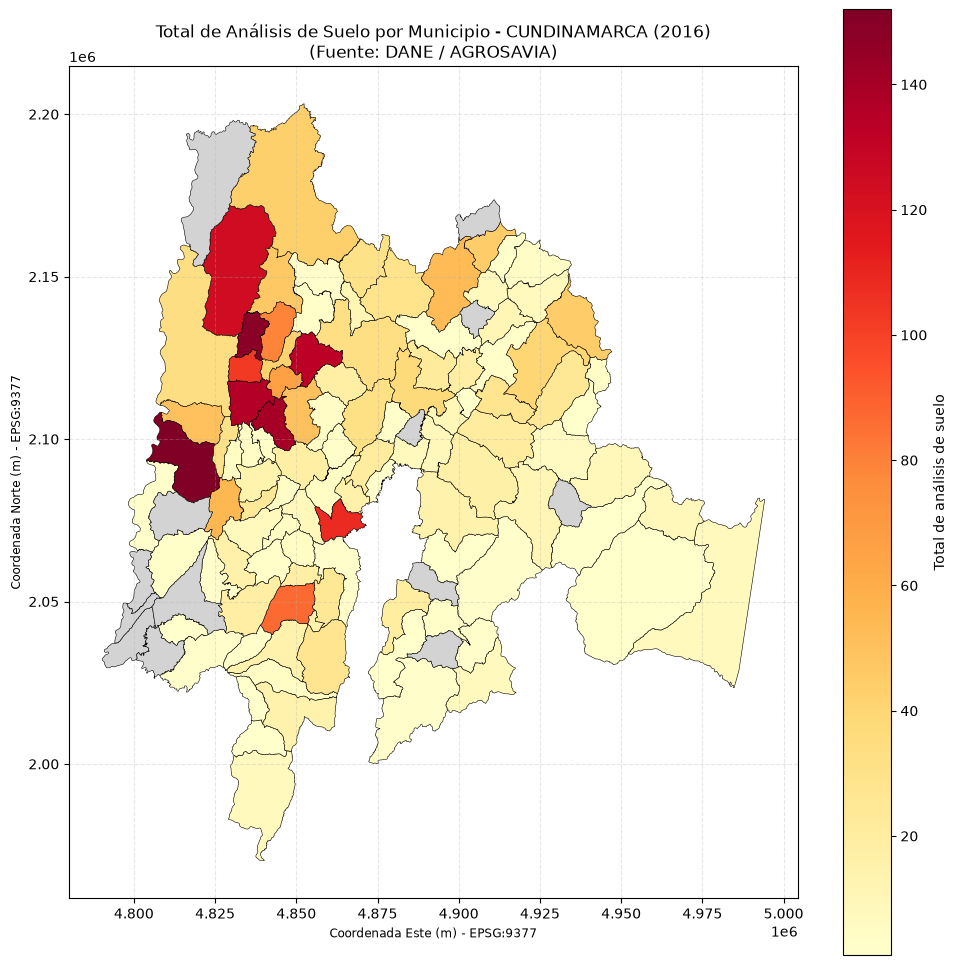

,codigo_municipio,total_analisis,media_ph_valido,area_ha
0,05001,1.0,5.650000,37474.148450
1,05002,2.0,6.740000,50695.978227
2,05004,NaN,NaN,29697.418845
3,05021,NaN,NaN,12885.643129
4,05030,17.0,5.158824,8411.714470


In [8]:
# 7. Integración de tabla y polígonos, mapa y área

# Elegir un año presente en AGROSAVIA y resumir análisis a una fila por municipio
anio_elegido = suelo_integrado["anio"].dropna().value_counts().index[0]
suelo_anio = suelo_integrado[suelo_integrado["anio"] == anio_elegido].copy()

# Crear el resumen anual con total, pH válidos y media de pH válido
suelo_anio["ph_para_media"] = np.where(
    suelo_anio["ph_valido"], suelo_anio["ph"], np.nan
)

resumen_anual = suelo_anio.groupby("codigo_municipio", as_index=False).agg(
    total_analisis=("id_fila", "count"),
    cantidad_ph_valido=("ph_valido", "sum"),
    media_ph_valido=("ph_para_media", "mean"),
)

resumen_anual["anio"] = anio_elegido

# En municipios_validos, crear codigo_municipio a partir de mpio_cdpmp como texto
muni_base = municipios_validos.copy()
muni_base["codigo_municipio"] = (
    muni_base["mpio_cdpmp"].astype(str).str.strip().str.zfill(5)
)

# Merge estricto validate="one_to_one" guardado en mapa_municipal
mapa_municipal = muni_base.merge(
    resumen_anual,
    on="codigo_municipio",
    how="left",
    validate="one_to_one",
    indicator=True,
)

# Separar y mostrar municipios sin resumen y códigos del resumen sin geometría
muni_sin_resumen = mapa_municipal[mapa_municipal["_merge"] == "left_only"][
    "codigo_municipio"
]
resumen_sin_geom = resumen_anual[
    ~resumen_anual["codigo_municipio"].isin(mapa_municipal["codigo_municipio"])
]

print("Resumen")
print(f"Año seleccionado para el análisis: {anio_elegido}")
print(f"Polígonos aptos conservados tras merge: {len(mapa_municipal)}")
print(f"Municipios sin resumen en el año {anio_elegido}: {len(muni_sin_resumen)}")
print(f"Códigos del resumen sin geometría DANE: {len(resumen_sin_geom)}")

# Reproyección a EPSG:9377 y cálculo del área en hectáreas (area_ha)
mapa_municipal_9377 = mapa_municipal.to_crs(epsg=9377)
mapa_municipal_9377["area_ha"] = mapa_municipal_9377["geometry"].area / 10000

print(f"\nCRS activo: EPSG:{mapa_municipal_9377.crs.to_epsg()}")
print(
    f"Área promedio municipal: {mapa_municipal_9377['area_ha'].mean():.2f} ha"
)
print(f"Área total cubierta: {mapa_municipal_9377['area_ha'].sum():.2f} ha\n")

# Generación y guardado del mapa temático por departamento
# Obtención del código de departamento (2 primeros dígitos DANE) con más muestras
cod_depto_elegido = (
    suelo_anio[
        suelo_anio["codigo_municipio"].isin(mapa_municipal["codigo_municipio"])
    ]["codigo_municipio"].str[:2].value_counts().index[0])

# Obtener el nombre del departamento asociado (para títulos)
nombre_depto_elegido = (
    suelo_anio[suelo_anio["codigo_municipio"].str[:2] == cod_depto_elegido][
        "nombre_departamento"].iloc[0]
    if "nombre_departamento" in suelo_anio.columns
    else f"Depto {cod_depto_elegido}")

# Filtro mapa_municipal_9377 con los 2 primeros dígitos de codigo_municipio
gdf_depto = mapa_municipal_9377[
    mapa_municipal_9377["codigo_municipio"].str[:2] == cod_depto_elegido].copy()

# Categoría visible para datos ausentes
gdf_depto["total_analisis_cat"] = (gdf_depto["total_analisis"].fillna("Sin datos").astype(str))

fig, ax = plt.subplots(figsize=(10, 10))

gdf_depto.plot(column="total_analisis",cmap="YlOrRd",
    legend=True,missing_kwds={"color": "lightgrey", "label": "Sin datos"},
    edgecolor="black",linewidth=0.4,ax=ax,legend_kwds={"label": "Total de análisis de suelo"},)

plt.title(
    f"Total de Análisis de Suelo por Municipio - {nombre_depto_elegido}"
    f" ({anio_elegido})\n(Fuente: DANE / AGROSAVIA)",
    fontsize=12,)
plt.xlabel("Coordenada Este (m) - EPSG:9377")
plt.ylabel("Coordenada Norte (m) - EPSG:9377")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()

# Guardar mapa de análisis como imagen
plt.savefig("mapa_analisis.png", dpi=300)
plt.show()

# Visualización
cols_existentes = [c for c in ["codigo_municipio",
        "total_analisis","media_ph_valido","area_ha",]
    if c in mapa_municipal_9377.columns]
display(mapa_municipal_9377[cols_existentes].head(5))

Resultados de la superposición
Piezas totales generadas: 9
Contactos de área cero descartados: 0
Piezas poligonales válidas (intersecciones): 9
Área total intersectada: 4545.23 ha

Contraste por Polígono IGAC (Área Original vs. Suma Intersectada):


,id_igac_orig,area_orig_ha,area_intersectada_sum_ha,diferencia_ha
0,0,1597.896924,1597.896924,9.322321e-12
1,1,359.443210,359.443210,1.136868e-13
2,2,1288.865623,1288.865623,5.229595e-12
3,3,876.420920,876.420920,5.684342e-13
4,4,422.606857,422.606857,0.000000e+00


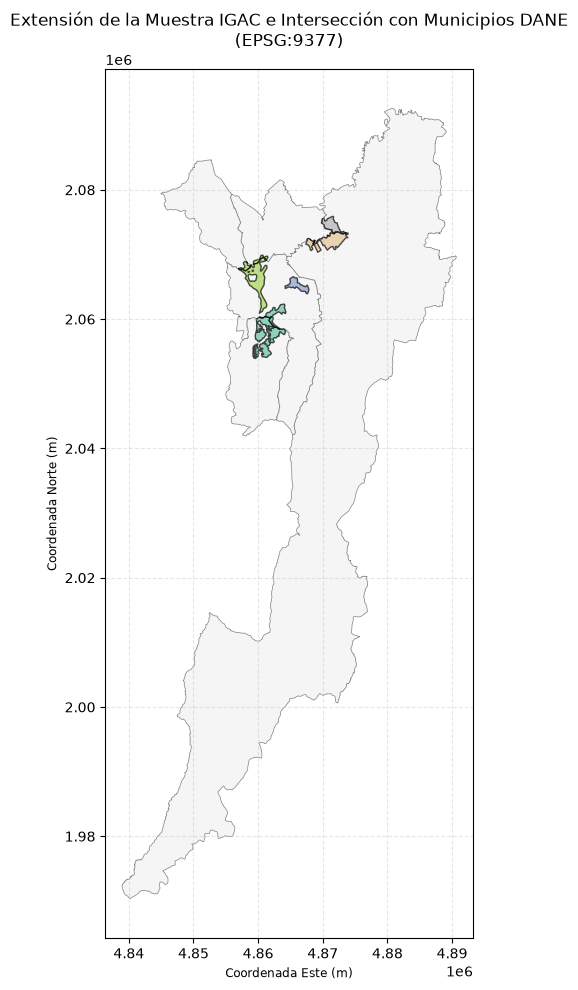

,codigo_municipio,total_analisis,area_intersectada_ha
0,05001,1.0,0.0
1,05002,2.0,0.0
2,05004,NaN,0.0
3,05021,NaN,0.0
4,05030,17.0,0.0


In [9]:
# 8 Intersección espacial con la muestra IGAC

# Proyectar copias de municipios_validos y capacidad_valida a EPSG:9377
municipios_m = municipios_validos.to_crs(epsg=9377).copy()
capacidad_m = capacidad_valida.to_crs(epsg=9377).copy()

# Crear código municipal estándar de 5 dígitos
municipios_m["codigo_municipio"] = (
    municipios_m["mpio_cdpmp"].astype(str).str.strip().str.zfill(5)
)

# Conservar una columna que identifique cada polígono IGAC a partir de su fila original y calcular su área original
capacidad_m["id_igac_orig"] = capacidad_m.index
capacidad_m["area_orig_ha"] = capacidad_m["geometry"].area / 10000

# Seleccionar solo atributos necesarios evitando nombres de columnas duplicados
cols_muni = ["codigo_municipio", "geometry"]
cols_igac = ["id_igac_orig", "area_orig_ha", "geometry"]

# Ejecución directa del overlay con los parámetros exigidos
overlay_raw = gpd.overlay(municipios_m[cols_muni],
    capacidad_m[cols_igac],how="intersection",keep_geom_type=False,
    make_valid=False,)

# Inspeccionar tipos resultantes, registrar contactos de área cero y conservar piezas poligonales de área positiva
overlay_raw["area_pieza_ha"] = overlay_raw["geometry"].area / 10000
contactos_cero = overlay_raw[overlay_raw["area_pieza_ha"] <= 0]

# Conservar piezas poligonales aptas en 'intersecciones'
intersecciones = overlay_raw[
    overlay_raw["geometry"].geom_type.isin(["Polygon", "MultiPolygon"])
    & (overlay_raw["area_pieza_ha"] > 0)].copy()

print("Resultados de la superposición")
print(f"Piezas totales generadas: {len(overlay_raw)}")
print(f"Contactos de área cero descartados: {len(contactos_cero)}")
print(f"Piezas poligonales válidas (intersecciones): {len(intersecciones)}")
print(f"Área total intersectada: {intersecciones['area_pieza_ha'].sum():.2f} ha\n")

# Contraste por polígono IGAC entre área original y suma intersectada
contraste_igac = (
    intersecciones.groupby("id_igac_orig")
    .agg(area_orig_ha=("area_orig_ha", "first"),
        area_intersectada_sum_ha=("area_pieza_ha", "sum"),).reset_index())
contraste_igac["diferencia_ha"] = (
    contraste_igac["area_orig_ha"] - contraste_igac["area_intersectada_sum_ha"])

print("Contraste por Polígono IGAC (Área Original vs. Suma Intersectada):")
display(contraste_igac)

# Resumir área intersectada por municipio e integrar a mapa_municipal con validate="one_to_one"
resumen_interseccion_mpio = (
    intersecciones.groupby("codigo_municipio", as_index=False)
    .agg(area_intersectada_ha=("area_pieza_ha", "sum")))

# Eliminar columna previa si ya existía en mapa_municipal (para evitar conflictos de sufijos)
if "area_intersectada_ha" in mapa_municipal.columns:
  mapa_municipal = mapa_municipal.drop(columns=["area_intersectada_ha"])

mapa_municipal = mapa_municipal.merge(resumen_interseccion_mpio,on="codigo_municipio",how="left",validate="one_to_one",)
mapa_municipal["area_intersectada_ha"] = mapa_municipal["area_intersectada_ha"].fillna(0)

# Generación y guardado del mapa 
fig, ax = plt.subplots(figsize=(10, 10))

# Extensión amplia del contexto municipal afectado
mpios_afectados = municipios_m[
    municipios_m["codigo_municipio"].isin(intersecciones["codigo_municipio"])]

mpios_afectados.plot(ax=ax, color="whitesmoke", edgecolor="gray", linewidth=0.5)
intersecciones.plot(ax=ax, column="id_igac_orig", cmap="Set2", alpha=0.7, edgecolor="black")

plt.title(
    "Extensión de la Muestra IGAC e Intersección con Municipios DANE\n(EPSG:9377)",
    fontsize=12,)

plt.xlabel("Coordenada Este (m)")
plt.ylabel("Coordenada Norte (m)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig("mapa_interseccion.png", dpi=300)
plt.show()

# Visualización 
cols_deseadas = ["codigo_municipio","total_analisis","area_ha","area_intersectada_ha",]
cols_visibles = [c for c in cols_deseadas if c in mapa_municipal.columns]

display(mapa_municipal[cols_visibles].head())

In [10]:
# 9 Publicación y relectura


# Exportación y relectura del Parquet tabular

ruta_parquet = os.path.join(OUT, "analisis_integrados.parquet")

# Asegurar que codigo_departamento y codigo_municipio queden como texto
suelo_integrado["codigo_departamento"] = suelo_integrado["codigo_departamento"].astype(str)
suelo_integrado["codigo_municipio"] = suelo_integrado["codigo_municipio"].astype(str)

# Exportar a Parquet
suelo_integrado.to_parquet(ruta_parquet,engine="pyarrow",compression="snappy",index=False)

# Relectura y verificación con pd.testing.assert_frame_equal
df_parquet_releido = pd.read_parquet(ruta_parquet, engine="pyarrow")

# Ordenar por id_fila para comparación
df_orig_ord = suelo_integrado.sort_values("id_fila").reset_index(drop=True)
df_releido_ord = df_parquet_releido.sort_values("id_fila").reset_index(drop=True)

pd.testing.assert_frame_equal(df_orig_ord, df_releido_ord)
print(" Verification Parquet: La relectura es idéntica al dataframe original.")

# Exportar a CSV de controles, equivalencias y pendientes
if 'controles_df' in globals():
    controles_df.to_csv(os.path.join(OUT, "controles.csv"), index=False)
if 'equivalencias_df' in globals():
    equivalencias_df.to_csv(os.path.join(OUT, "equivalencias.csv"), index=False)
if 'resumen_df' in globals():
    resumen_df.to_csv(os.path.join(OUT, "resumen.csv"), index=False)
if 'pendientes_df' in globals():
    pendientes_df.to_csv(os.path.join(OUT, "registros_pendientes.csv"), index=False)

# Preparación de GeoDataFrames y conversión de tipos categóricos/merge
ruta_gpkg = os.path.join(OUT, "resultados_espaciales.gpkg")

# Eliminar GPKG anterior si existe 
if os.path.exists(ruta_gpkg):
    os.remove(ruta_gpkg)

# Copias de trabajo
gdf_municipios_exp = mapa_municipal.copy()
gdf_intersecciones_exp = intersecciones.copy()

# Convertir explícitamente columnas categóricas o tipos especiales (_merge) a texto
for col in gdf_municipios_exp.columns:
    if isinstance(gdf_municipios_exp[col].dtype, pd.CategoricalDtype) or col == "_merge":
        gdf_municipios_exp[col] = gdf_municipios_exp[col].astype(str)

for col in gdf_intersecciones_exp.columns:
    if isinstance(gdf_intersecciones_exp[col].dtype, pd.CategoricalDtype) or col == "_merge":
        gdf_intersecciones_exp[col] = gdf_intersecciones_exp[col].astype(str)

# Limpieza de columnas duplicadas o del motor GIS
cols_a_eliminar = [c for c in gdf_intersecciones_exp.columns if c.startswith("Shape_") or c.startswith("OBJECTID")]
if cols_a_eliminar:
    gdf_intersecciones_exp = gdf_intersecciones_exp.drop(columns=cols_a_eliminar)

# Exportación explícita de capas al GeoPackage
gdf_municipios_exp.to_file(ruta_gpkg,layer="municipios",driver="GPKG",engine="pyogrio",index=False)

gdf_intersecciones_exp.to_file(ruta_gpkg,layer="intersecciones",driver="GPKG",engine="pyogrio",index=False)

print(f"\nGeoPackage publicado exitosamente en: {ruta_gpkg}")
print(f"Tamaño final del archivo: {os.path.getsize(ruta_gpkg) / 1024:.2f} KB")

# verificación de capas (desde GeoPackage)
municipios_gpkg = gpd.read_file(ruta_gpkg, layer="municipios", engine="pyogrio")
intersecciones_gpkg = gpd.read_file(ruta_gpkg, layer="intersecciones", engine="pyogrio")

print("\n Sobre el Geopackage")
print(f"Capa 'municipios'     -> Filas: {len(municipios_gpkg)}, CRS: EPSG:{municipios_gpkg.crs.to_epsg()}")
print(f"Capa 'intersecciones' -> Filas: {len(intersecciones_gpkg)}, CRS: EPSG:{intersecciones_gpkg.crs.to_epsg()}")

# Verificación de consistencia de áreas retenidas
area_orig_sum = gdf_municipios_exp["area_ha"].sum() if "area_ha" in gdf_municipios_exp.columns else 0
area_releida_sum = municipios_gpkg["area_ha"].sum() if "area_ha" in municipios_gpkg.columns else 0
print(f"Diferencia de área retenida en municipios: {abs(area_orig_sum - area_releida_sum):.4f} ha")

 Verification Parquet: La relectura es idéntica al dataframe original.

GeoPackage publicado exitosamente en: /home/tuptc/big-data-postgraduate/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg
Tamaño final del archivo: 98384.00 KB

 Sobre el Geopackage
Capa 'municipios'     -> Filas: 1122, CRS: EPSG:4326
Capa 'intersecciones' -> Filas: 9, CRS: EPSG:9377
Diferencia de área retenida en municipios: 0.0000 ha


### Conclusiones

1. **Alta Cobertura**
   La realización del proceso de limpieza (normalización Unicode, mayúsculas y formateo de códigos DANE) con el uso del diccionario de equivalencias permitió vincular **99.71%** de los datos con la DIVIPOLA, demostrando que la homologación de texto resuelve la mayoría de discrepancias en nombres de municipios.

2. **Garantía de Trazabilidad y Control de Calidad:**
   Se logró un buen control de información al no eliminar filas del conjunto original. Los 271 registros no asociados y las lecturas atípicas de pH (fuera del rango 0 a 14) fueron aislados y tratados de forma transparente, asegurando que la suma de salidas coincida exactamente con la entrada inicial.

3. **Preparación para la entrega y uso en la siguiente fase**
   Tanto la creación de la clave única `id_fila` como el cálculo del resumen territorial siguieron la integridad de los datos. El guardado final en Parquet como `analisis_integrados.parquet` en la carpeta del proyecto asegura una buena disposición para ser consumida en el del siguiente taller.